# Fetal Head Circumference (HC) and Gestational Age Estimation

Computer Vision only pipeline:

USG Image → Preprocessing → Edge Detection → Ellipse Detection → HC → GA

Tidak menggunakan Machine Learning.


In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import math


In [21]:
# ==============================
# PARAMETER SETTING
# ==============================

IMAGE_PATH = "773_2HC.png"

HC_REF_MM = 292.20 

# Kalibrasi (mm / pixel)
PIXEL_SIZE_MM = 0.221600823932

# CLAHE
CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

# Median Filter
MEDIAN_KERNEL = 3

# Canny Edge
CANNY_LOW = 75
CANNY_HIGH = 150

# Hough Circle
HOUGH_DP = 1.2
HOUGH_MIN_DIST = 80
HOUGH_PARAM1 = 100
HOUGH_PARAM2 = 35
MIN_RADIUS = 120
MAX_RADIUS = 280


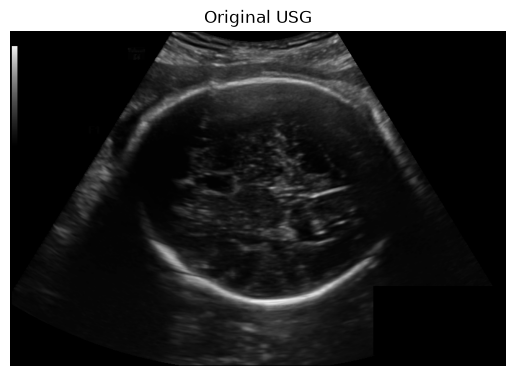

In [22]:

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError("Image tidak ditemukan")

rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(rgb)
plt.title("Original USG")
plt.axis("off")
plt.show()


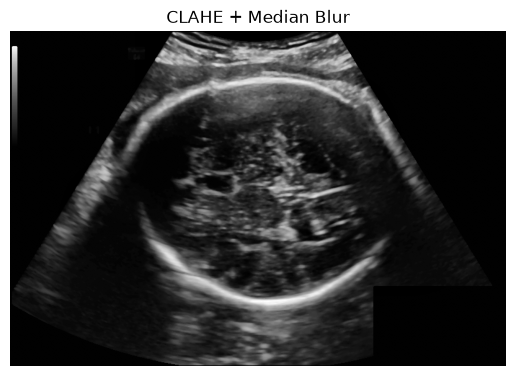

In [23]:

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

clahe = cv2.createCLAHE(
    clipLimit=CLAHE_CLIP,
    tileGridSize=CLAHE_GRID
)

enhanced = clahe.apply(gray)

blur = cv2.medianBlur(
    enhanced,
    MEDIAN_KERNEL
)

plt.imshow(blur,cmap="gray")
plt.title("CLAHE + Median Blur")
plt.axis("off")
plt.show()


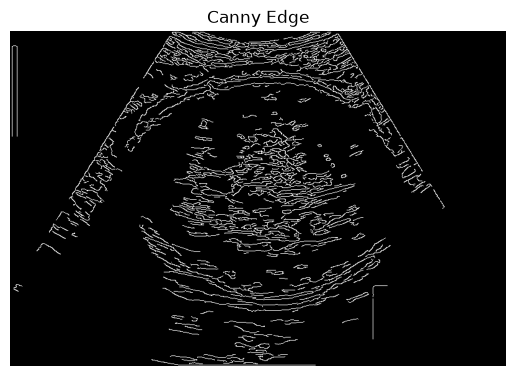

In [24]:

edges=cv2.Canny(
    blur,
    CANNY_LOW,
    CANNY_HIGH
)

plt.imshow(edges,cmap="gray")
plt.title("Canny Edge")
plt.axis("off")
plt.show()


In [25]:
# ==========================================
# DETEKSI KEPALA: HOUGH CIRCLE + REFINE ELLIPSE
# ==========================================
ellipse = None
H, W = img.shape[:2]

if edges is None:
    print("[ERROR] Edge map tidak tersedia -> deteksi dilewati.")

else:
    # --- 1. Hough Circle: cari kandidat pusat & radius kepala ---
    circles = None
    try:
        circles = cv2.HoughCircles(
            blur,
            cv2.HOUGH_GRADIENT,
            dp=HOUGH_DP,
            minDist=HOUGH_MIN_DIST,
            param1=HOUGH_PARAM1,
            param2=HOUGH_PARAM2,
            minRadius=MIN_RADIUS,
            maxRadius=MAX_RADIUS
        )
    except cv2.error as e:
        print(f"[ERROR] HoughCircles gagal: {e}")

    if circles is None:
        print("[WARNING] Hough tidak menemukan kandidat lingkaran kepala.")
    else:
        circles = np.uint16(np.around(circles))
        print(f"[INFO] {len(circles[0])} kandidat lingkaran ditemukan.")

        # Titik tepi
        ys, xs = np.where(edges > 0)
        pts = np.column_stack((xs, ys)).astype(np.float64)

        # --- 2. Pilih lingkaran terbaik via dukungan tepi (edge support) ---
        best_c, best_support = None, -1
        for c in circles[0]:
            cx, cy, r = float(c[0]), float(c[1]), float(c[2])
            d = np.abs(np.sqrt((pts[:, 0] - cx) ** 2 + (pts[:, 1] - cy) ** 2) - r)
            support = int((d < 3).sum())  
            if support > best_support:
                best_support, best_c = support, (cx, cy, r)

    if best_c is None:
        print("[WARNING] Tidak ada kandidat lingkaran valid.")
    else:
        cx, cy, r = best_c
        print(f"[INFO] Lingkaran terpilih: center=({cx:.0f},{cy:.0f}) radius={r:.0f} (support={best_support})")

        # --- 3. Refine: fit ellipse ke titik tepi di annulus sekitar lingkaran ---
        # ANNULUS = 20 (hardcoded)
        dist = np.sqrt((pts[:, 0] - cx) ** 2 + (pts[:, 1] - cy) ** 2)
        mask = (dist > r - 20) & (dist < r + 20)  # ANNULUS = 20
        sel = pts[mask]
        print(f"[INFO] Titik tepi di annulus: {len(sel)}")

        if len(sel) < 5:
            print("[WARNING] Titik annulus < 5 -> tidak cukup untuk fitEllipse.")
        else:
            try:
                e = cv2.fitEllipse(sel.astype(np.float32).reshape(-1, 1, 2))
                (ecx, ecy), (ax1, ax2), ang = e
                maj, mi = max(ax1, ax2), min(ax1, ax2)
                if mi <= 0:
                    print("[WARNING] Sumbu ellipse tidak valid -> pakai lingkaran.")
                else:
                    ellipse = e
                    print("[INFO] Ellipse terpilih:", ellipse)
            except cv2.error as err:
                print(f"[WARNING] fitEllipse gagal: {err}")

        # --- 4. Fallback: pakai lingkaran Hough (kepala mendekati bulat) ---
        if ellipse is None:
            ellipse = ((float(cx), float(cy)), (float(2 * r), float(2 * r)), 0.0)
            print("[INFO] Fallback -> ellipse dari lingkaran:", ellipse)
        else:
            print("[INFO] Ellipse terpilih:", ellipse)

    if ellipse is None:
        print("[ERROR] Ellipse kepala tidak terdeteksi.")
        print("[INFO] Saran: sesuaikan HOUGH_PARAM2, MIN_RADIUS/MAX_RADIUS, atau CANNY.")


[INFO] 29 kandidat lingkaran ditemukan.
[INFO] Lingkaran terpilih: center=(423,237) radius=213 (support=1076)
[INFO] Titik tepi di annulus: 5824
[INFO] Ellipse terpilih: ((419.9751281738281, 234.0521240234375), (421.6299133300781, 430.6781005859375), 89.01927185058594)
[INFO] Ellipse terpilih: ((419.9751281738281, 234.0521240234375), (421.6299133300781, 430.6781005859375), 89.01927185058594)


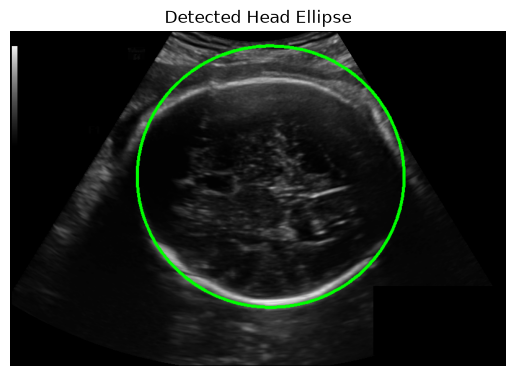

In [26]:

result=rgb.copy()

cv2.ellipse(
    result,
    ellipse,
    (0,255,0),
    3
)

plt.imshow(result)
plt.title("Detected Head Ellipse")
plt.axis("off")
plt.show()


In [27]:

(center,axes,angle)=ellipse

major=max(axes)/2
minor=min(axes)/2

a_mm=major*PIXEL_SIZE_MM
b_mm=minor*PIXEL_SIZE_MM

HC_mm=np.pi*(
    3*(a_mm+b_mm)
    -
    np.sqrt(
        (3*a_mm+b_mm)*(a_mm+3*b_mm)
    )
)

print("Semi major axis:",a_mm,"mm")
print("Semi minor axis:",b_mm,"mm")
print("HC:",HC_mm,"mm")


Semi major axis: 47.71931096965626 mm
Semi minor axis: 46.71676809416153 mm
HC: 296.6880513473297 mm


In [28]:

HC=HC_mm

log_GA=(
    0.05970*(math.log(HC)**2)
    +
    6.409e-9*(HC**3)
    +
    3.3258
)

GA_days=math.exp(log_GA)

print("Estimated GA:")
print(GA_days/7,"weeks")


Estimated GA:
32.52275503233196 weeks


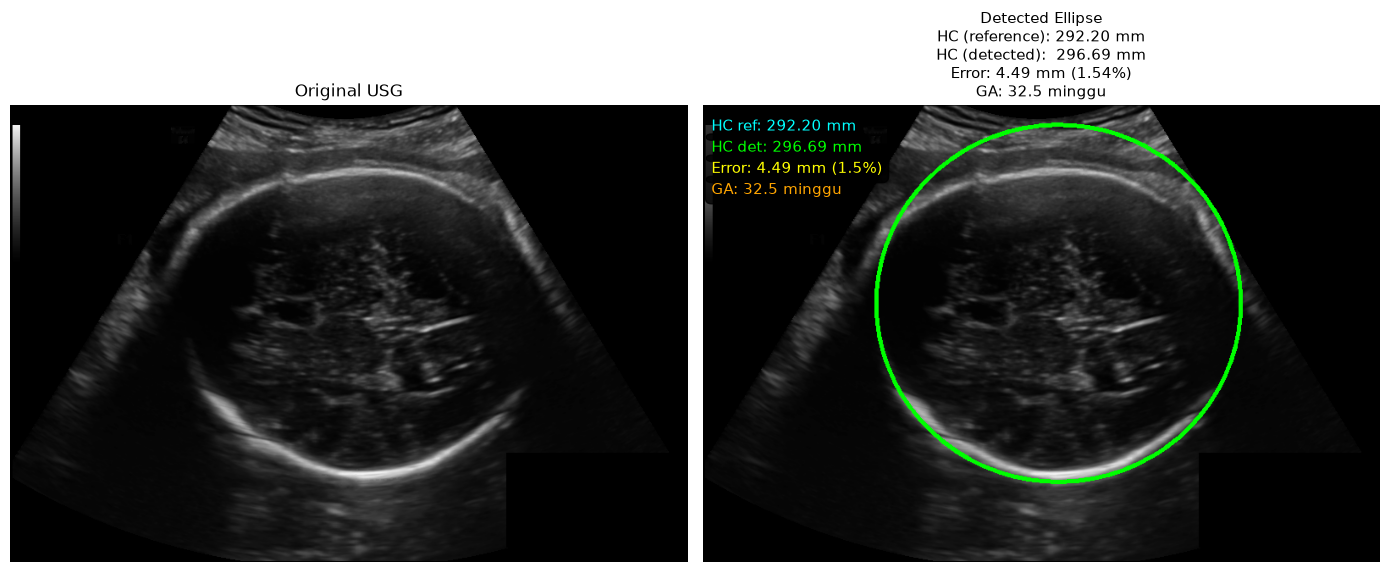

In [29]:
# ==========================================
# NILAI ACUAN HC (ganti sesuai ground truth)
# ==========================================

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original USG")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)

# Overlay teks: HC reference vs detected + GA
if ellipse is not None and HC_mm is not None:
    err = abs(HC_mm - HC_REF_MM)
    err_pct = 100 * err / HC_REF_MM
    title = "Detected Ellipse\n"
    title += "HC (reference): {:.2f} mm\n".format(HC_REF_MM)
    title += "HC (detected):  {:.2f} mm\n".format(HC_mm)
    title += "Error: {:.2f} mm ({:.2f}%)\n".format(err, err_pct)

    # Tambah nilai GA
    if HC_mm > 0:
        HC = HC_mm
        log_GA = (
            0.05970 * (math.log(HC) ** 2)
            + 6.409e-9 * (HC ** 3)
            + 3.3258
        )
        GA_days = math.exp(log_GA)
        GA_weeks = GA_days / 7
        title += "GA: {:.1f} minggu".format(GA_weeks)

    plt.text(10, 30, "HC ref: {:.2f} mm".format(HC_REF_MM), color="cyan", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.text(10, 55, "HC det: {:.2f} mm".format(HC_mm), color="lime", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.text(10, 80, "Error: {:.2f} mm ({:.1f}%)".format(err, err_pct), color="yellow", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.text(10, 105, "GA: {:.1f} minggu".format(GA_weeks), color="orange", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
else:
    title = "Ellipse tidak terdeteksi"

plt.title(title, fontsize=11)
plt.axis("off")

plt.tight_layout()
plt.show()